# CLINC150 — Exploratory Data Analysis

CLINC150 содержит короткие англоязычные запросы с метками пользовательских намерений. Здесь рассматриваются структура данных, качество разбиений и сходство текстов. Эти характеристики понадобятся для исследования классификации и обнаружения Out-of-Scope (OOS) запросов при K = 10, 20 и 30 поддерживаемых намерениях.

Анализ разделён на три части: **Structure Investigation**, **Quality Investigation**, **Content Investigation** — по подходу [Michael Notter, *Advanced EDA*](https://miykael.github.io/blog/2022/advanced_eda/).

Исходные разбиения не меняются. В лексическом анализе TF-IDF обучается только на In-Scope `train`. Тестовые данные используются для описания датасета, но не для выбора классов и параметров модели. Обучения классификатора и оценки его качества здесь нет.

Данные: [CLINC150 / oos-eval (Larson et al., 2019)](https://github.com/clinc/oos-eval), лицензия CC BY 3.0.

In [1]:
from collections import Counter
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from src.data_loader import load_json

**Необязательно: скачивание данных.** Если в папке `data/` ещё нет `data_full.json` и `domains.json`, поменяйте `DOWNLOAD_DATA` на `True` и выполните следующую ячейку. При обычном запуске скачивание отключено.

In [2]:
DOWNLOAD_DATA = False

if DOWNLOAD_DATA:
    from src.download_data import main

    main()

## 1. Structure Investigation

### 1.1. Файлы и разбиения

В `data_full.json` каждый запрос представлен парой `[text, intent]`. Ключи `train`, `val`, `test` обозначают исходные разбиения известных намерений, а `oos_train`, `oos_val`, `oos_test` — исходные OOS-запросы. Файл `domains.json` объединяет известные намерения в тематические домены.

In [3]:
data = load_json("data_full.json")
domains = load_json("domains.json")

print("Разбиения:", list(data))
print("Формат записи:", data["train"][0][:2])

Разбиения: ['oos_val', 'val', 'train', 'oos_test', 'test', 'oos_train']
Формат записи: ['what expression would i use to say i love you if i were an italian', 'translate']


In [4]:
splits = {
    name: pd.DataFrame(records, columns=["text", "intent"])
    for name, records in data.items()
}
df_train, df_val, df_test = (splits[name] for name in ("train", "val", "test"))

split_order = ["train", "val", "test", "oos_train", "oos_val", "oos_test"]
summary = pd.DataFrame([
    {
        "split": name,
        "type": "In-Scope" if not name.startswith("oos_") else "Original OOS",
        "requests": len(splits[name]),
        "unique_labels": splits[name]["intent"].nunique(),
    }
    for name in split_order
]).set_index("split")
display(summary)
print("Всего запросов:", summary["requests"].sum())

,type,requests,unique_labels
split,,,
train,In-Scope,15000,150
val,In-Scope,3000,150
test,In-Scope,4500,150
oos_train,Original OOS,100,1
oos_val,Original OOS,100,1
oos_test,Original OOS,1000,1


Всего запросов: 23700


CLINC150 содержит 150 известных намерений: 15 000 запросов в `train`, 3 000 в `val` и 4 500 в `test`. Для Original OOS предусмотрено 100, 100 и 1 000 запросов соответственно. Всего — **23 700 запросов**.

### 1.2. Баланс классов и домены

In [5]:
intent_counts = pd.DataFrame({
    name: splits[name]["intent"].value_counts()
    for name in ("train", "val", "test")
})
display(intent_counts.agg(["min", "median", "max"]).astype(int))

domain_df = pd.DataFrame([
    {"domain": domain, "intent": intent}
    for domain, intents in domains.items()
    for intent in intents
])
domain_summary = domain_df.groupby("domain")["intent"].nunique().sort_index()
display(domain_summary.rename("intents").to_frame())
print("Доменов:", len(domains), "| намерений в словаре доменов:", len(domain_df))

,train,val,test
min,100,20,30
median,100,20,30
max,100,20,30


,intents
domain,
auto_and_commute,15
banking,15
credit_cards,15
home,15
kitchen_and_dining,15
meta,15
small_talk,15
travel,15
utility,15


Доменов: 10 | намерений в словаре доменов: 150


В каждом известном намерении по **100 запросов в train, 20 в val и 30 в test**. Все 150 намерений распределены по **10 доменам**, по 15 в каждом.

### 1.3. Примеры In-Scope и Original OOS

In [6]:
display(pd.concat([
    df_train.sample(3, random_state=42).assign(group="In-Scope train"),
    splits["oos_test"].sample(3, random_state=42).assign(group="Original OOS test"),
], ignore_index=True)[["group", "text", "intent"]])

,group,text,intent
0,In-Scope train,should i get any vaccines before going over to...,vaccines
1,In-Scope train,i am going to go ahead and pair this with my n...,sync_device
2,In-Scope train,please play my taylor swift mix,play_music
3,Original OOS test,can you colorize a black and white photo,oos
4,Original OOS test,accept incoming phone call,oos
5,Original OOS test,what do i put on my feet,oos


Метка `oos` относится к запросам за пределами поддерживаемых функций. Это не отдельный тематический домен: OOS-запрос может содержать те же слова, что и запрос известного класса.

## 2. Quality Investigation

### 2.1. Пропуски, метки и повторы внутри разбиений

Проверяются пустые и некорректные значения, неизвестные метки, дубликаты пар `(text, intent)` и повторы одного текста. Для сравнения используется временная нормализация: перевод в нижний регистр и удаление лишних пробелов. Исходные строки не изменяются.

In [7]:
all_known_intents = set(domain_df["intent"])

def normalize_text(text):
    return " ".join(text.casefold().split())

quality_rows = []
for name in split_order:
    frame = splits[name]
    valid_text = frame["text"].map(lambda value: isinstance(value, str))
    valid_label = frame["intent"].map(lambda value: isinstance(value, str))
    usable = frame.loc[valid_text].copy()
    expected = {"oos"} if name.startswith("oos_") else all_known_intents
    normalized = usable["text"].map(normalize_text)
    quality_rows.append({
        "split": name,
        "missing_values": int(frame.isna().sum().sum()),
        "invalid_text_types": int((~valid_text).sum()),
        "empty_text": int(normalized.eq("").sum()),
        "invalid_or_unknown_labels": int((~valid_label | ~frame["intent"].isin(expected)).sum()),
        "exact_row_duplicates": int(frame.duplicated().sum()),
        "duplicate_texts_exact": int(usable["text"].duplicated().sum()),
        "duplicate_texts_normalized": int(normalized.duplicated().sum()),
        "conflicting_labels_normalized": int(
            pd.DataFrame({"normalized": normalized, "intent": usable["intent"]})
            .groupby("normalized")["intent"].nunique().gt(1).sum()
        ),
    })
quality = pd.DataFrame(quality_rows).set_index("split")
display(quality)

,missing_values,invalid_text_types,empty_text,invalid_or_unknown_labels,exact_row_duplicates,duplicate_texts_exact,duplicate_texts_normalized,conflicting_labels_normalized
split,,,,,,,,
train,0,0,0,0,0,0,0,0
val,0,0,0,0,0,0,0,0
test,0,0,0,0,0,0,0,0
oos_train,0,0,0,0,0,0,0,0
oos_val,0,0,0,0,0,0,0,0
oos_test,0,0,0,0,0,0,0,0


Пропусков, пустых запросов, неизвестных меток и дубликатов внутри отдельных разбиений не обнаружено — в том числе после простой нормализации. Это не исключает близких по смыслу перефразировок и спорной разметки.

### 2.2. Совпадения между разбиениями

In [8]:
texts_exact = {name: set(splits[name]["text"]) for name in split_order}
texts_norm = {
    name: {normalize_text(text) for text in splits[name]["text"]}
    for name in split_order
}

cross_split_rows = []
for left, right in combinations(split_order, 2):
    common_exact = texts_exact[left] & texts_exact[right]
    common_norm = texts_norm[left] & texts_norm[right]
    cross_split_rows.append({
        "split_a": left,
        "split_b": right,
        "exact_shared": len(common_exact),
        "normalized_shared": len(common_norm),
        "in_scope_vs_oos": left.startswith("oos_") != right.startswith("oos_"),
    })
cross_split = pd.DataFrame(cross_split_rows)
display(cross_split.query("normalized_shared > 0"))
print("Всего совпадений в парах In-Scope ↔ Original OOS:",
      cross_split.loc[cross_split["in_scope_vs_oos"], "normalized_shared"].sum())

examples = []
for row in cross_split.itertuples(index=False):
    for text in sorted(texts_norm[row.split_a] & texts_norm[row.split_b])[:3]:
        first = splits[row.split_a].loc[
            splits[row.split_a]["text"].map(normalize_text).eq(text), "intent"
        ].iloc[0]
        second = splits[row.split_b].loc[
            splits[row.split_b]["text"].map(normalize_text).eq(text), "intent"
        ].iloc[0]
        examples.append({
            "text": text, "split_a": row.split_a, "intent_a": first,
            "split_b": row.split_b, "intent_b": second,
        })
display(pd.DataFrame(examples).head(8))

,split_a,split_b,exact_shared,normalized_shared,in_scope_vs_oos
0,train,val,3,3,False
1,train,test,2,2,False


Всего совпадений в парах In-Scope ↔ Original OOS: 0


,text,split_a,intent_a,split_b,intent_b
0,hey what's up,train,greeting,val,greeting
1,turn up your volume,train,whisper_mode,val,change_volume
2,what is on my to do list,train,todo_list,val,reminder
3,what's your designation,train,what_is_your_name,test,user_name
4,where did you grow up,train,how_old_are_you,test,where_are_you_from


Найдены **3 совпадающих текста между `train` и `val`** и **2 между `train` и `test`**. После нормализации дополнительных совпадений нет. Тексты In-Scope и Original OOS не пересекаются. Повторы не удалялись.

### 2.3. Соответствие intent → domain

In [9]:
mapping_counts = domain_df["intent"].value_counts()
domain_checks = pd.Series({
    "missing_intents_in_domains": len(set(df_train["intent"]) - set(domain_df["intent"])),
    "domains_intents_without_train_examples": len(set(domain_df["intent"]) - set(df_train["intent"])),
    "intents_in_multiple_domains": int(mapping_counts.gt(1).sum()),
    "domain_names": len(domains),
    "intents_in_domains": domain_df["intent"].nunique(),
}, name="count")
display(domain_checks.to_frame())

,count
missing_intents_in_domains,0
domains_intents_without_train_examples,0
intents_in_multiple_domains,0
domain_names,10
intents_in_domains,150


Все 150 известных намерений входят в `domains.json` ровно один раз. Метка `oos` не относится ни к одному из доменов.

## 3. Content Investigation

### 3.1. Длина запросов

Длина измеряется числом слов, разделённых пробелами. На графике сравниваются In-Scope `val` и Original OOS `oos_val`, чтобы не смешивать разные разбиения.

,median_words,mean_words,p90_words,min_words,max_words
split,,,,,
train,8.0,8.34,13.0,1,28
val,8.0,8.32,13.0,1,24
test,8.0,8.19,12.0,1,25
oos_train,7.0,7.06,10.0,3,13
oos_val,7.0,7.16,10.0,1,22
oos_test,8.0,8.75,13.0,1,20


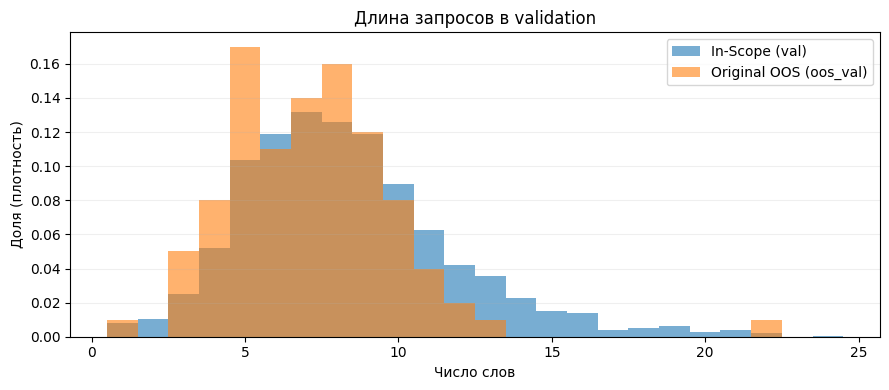

In [10]:
length_stats = []
for name in split_order:
    lengths = splits[name]["text"].str.split().str.len()
    length_stats.append({
        "split": name,
        "median_words": lengths.median(),
        "mean_words": round(lengths.mean(), 2),
        "p90_words": lengths.quantile(0.90),
        "min_words": lengths.min(),
        "max_words": lengths.max(),
    })
display(pd.DataFrame(length_stats).set_index("split"))

in_lengths = splits["val"]["text"].str.split().str.len()
oos_lengths = splits["oos_val"]["text"].str.split().str.len()
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(0.5, max(in_lengths.max(), oos_lengths.max()) + 1.5, 1)
ax.hist(in_lengths, bins=bins, density=True, alpha=0.6, label="In-Scope (val)")
ax.hist(oos_lengths, bins=bins, density=True, alpha=0.6, label="Original OOS (oos_val)")
ax.set(title="Длина запросов в validation", xlabel="Число слов", ylabel="Доля (плотность)")
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

Медианная длина In-Scope-запросов — **8 слов** во всех трёх разбиениях. Для Original OOS медиана составляет **7 слов** в `oos_train` и `oos_val`, **8 слов** в `oos_test`. Распределения сильно перекрываются.

#### Словарь и частые слова

Для подсчёта слов используется токенизация `TfidfVectorizer` по умолчанию: приведение к нижнему регистру и выделение буквенно-цифровых токенов длиной не менее двух символов. Стоп-слова сохраняются.

In [11]:
vectorizer = TfidfVectorizer()
analyzer = vectorizer.build_analyzer()

vocabulary_rows = []
for name in split_order:
    tokens = [token for text in splits[name]["text"] for token in analyzer(text)]
    vocabulary_rows.append({
        "split": name,
        "total_tokens": len(tokens),
        "unique_tokens": len(set(tokens)),
        "type_token_ratio": round(len(set(tokens)) / len(tokens), 3),
    })
display(pd.DataFrame(vocabulary_rows).set_index("split"))

word_counts = {
    "In-Scope validation": Counter(
        token for text in splits["val"]["text"] for token in analyzer(text)
    ),
    "Original OOS validation": Counter(
        token for text in splits["oos_val"]["text"] for token in analyzer(text)
    ),
}
common_words = pd.DataFrame({
    group: [f"{word} ({count})" for word, count in counts.most_common(12)]
    for group, counts in word_counts.items()
})
display(common_words.T.rename_axis("group"))

,total_tokens,unique_tokens,type_token_ratio
split,,,
train,116116,5026,0.043
val,23125,2312,0.100
test,34245,2700,0.079
oos_train,690,336,0.487
oos_val,687,320,0.466
oos_test,8312,2087,0.251


,0,1,2,3,4,5,6,7,8,9,10,11
group,,,,,,,,,,,,
In-Scope validation,my (1103),to (1050),the (735),what (592),you (562),for (522),is (502),how (456),me (429),do (421),in (339),on (336)
Original OOS validation,the (39),what (28),how (24),is (23),to (18),in (14),are (13),do (12),of (12),my (10),me (10),does (10)


В In-Scope `val` найдено **2 312 уникальных токенов**, в Original OOS `oos_val` — **320**. Выборки сильно различаются по размеру (3 000 и 100 запросов), поэтому их словарное разнообразие нельзя сравнивать только по абсолютному числу слов.

### 3.2. Лексическое пересечение с обучающим словарём

Словарь строится по всем 150 намерениям исходного In-Scope `train`. Для каждого запроса считается доля токенов, входящих в этот словарь. Повторные слова учитываются повторно. Сходство по отдельным словам не равно сходству по смыслу.

,median_fraction,mean_fraction,full_vocabulary_coverage,zero_tokens
split,,,,
val,1.000000,0.968,2445,0
oos_val,0.800000,0.797,23,0
test,1.000000,0.972,3728,0
oos_test,0.846154,0.828,210,0


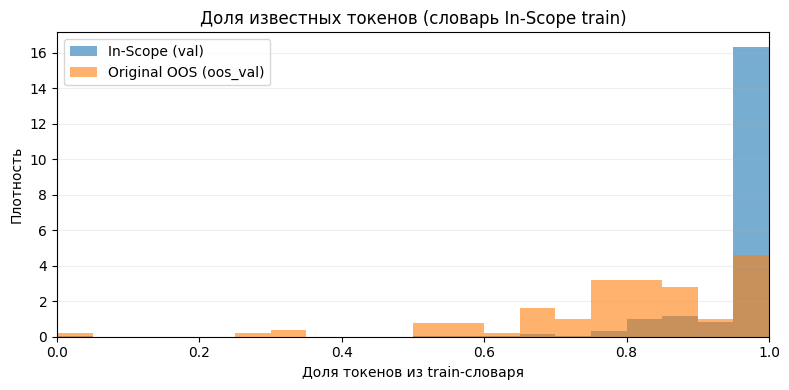

In [12]:
X_train = vectorizer.fit_transform(df_train["text"])
train_vocabulary = set(vectorizer.vocabulary_)
analyzer = vectorizer.build_analyzer()


def known_token_fraction(text):
    tokens = analyzer(text)
    return sum(token in train_vocabulary for token in tokens) / len(tokens) if tokens else np.nan

lexical_overlap = {
    name: splits[name]["text"].map(known_token_fraction)
    for name in ("val", "oos_val", "test", "oos_test")
}
lexical_summary = pd.DataFrame([
    {
        "split": name,
        "median_fraction": series.median(),
        "mean_fraction": round(series.mean(), 3),
        "full_vocabulary_coverage": int(series.eq(1.0).sum()),
        "zero_tokens": int(series.isna().sum()),
    }
    for name, series in lexical_overlap.items()
]).set_index("split")
display(lexical_summary)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(lexical_overlap["val"].dropna(), bins=np.linspace(0, 1, 21),
        density=True, alpha=0.60, label="In-Scope (val)")
ax.hist(lexical_overlap["oos_val"].dropna(), bins=np.linspace(0, 1, 21),
        density=True, alpha=0.60, label="Original OOS (oos_val)")
ax.set(title="Доля известных токенов (словарь In-Scope train)",
       xlabel="Доля токенов из train-словаря", ylabel="Плотность")
ax.set_xlim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

In [13]:
oos_examples = splits["oos_val"].copy()
oos_examples["known_token_fraction"] = lexical_overlap["oos_val"].to_numpy()
display(
    oos_examples.sort_values(
        ["known_token_fraction", "text"], ascending=[False, True]
    ).head(6)[["text", "known_token_fraction"]]
)

,text,known_token_fraction
22,am kind of busy now,1.0
19,are there any new companies to look out for,1.0
88,are white and brown eggs any different,1.0
97,can you tell me some fake news,1.0
47,can you tell me the latest georgia news,1.0
3,how do i find the area of a circle,1.0


В `val` медианная доля знакомых токенов равна **1,00** для In-Scope и **0,80** для Original OOS. При этом **23 из 100** OOS-запросов в `oos_val` целиком состоят из слов обучающего словаря. Следовательно, наличие известных слов само по себе не позволяет отличить поддерживаемый запрос от OOS.

### 3.3. Сходство намерений по TF-IDF

Каждое намерение представлено средним TF-IDF-вектором его запросов из `train`. Между этими векторами рассчитано косинусное сходство. Оно описывает близость текстовых представлений, но не частоту ошибок классификатора.

In [14]:
intent_names = sorted(df_train["intent"].unique())
train_labels = df_train["intent"].to_numpy()
centroids = np.vstack([
    np.asarray(X_train[train_labels == intent].mean(axis=0)).ravel()
    for intent in intent_names
])
similarities = cosine_similarity(centroids)
intent_to_domain = dict(zip(domain_df["intent"], domain_df["domain"]))

pairs = pd.DataFrame([
    {
        "intent_a": intent_names[i],
        "intent_b": intent_names[j],
        "cosine_similarity": similarities[i, j],
        "same_domain": intent_to_domain[intent_names[i]] == intent_to_domain[intent_names[j]],
    }
    for i in range(len(intent_names))
    for j in range(i + 1, len(intent_names))
]).sort_values("cosine_similarity", ascending=False, ignore_index=True)
display(pairs.head(10).round({"cosine_similarity": 3}))
display(pairs.groupby("same_domain")["cosine_similarity"].agg(
    ["count", "median", "mean"]
).round(3).rename(index={True: "same domain", False: "different domains"}))

,intent_a,intent_b,cosine_similarity,same_domain
0,credit_score,improve_credit_score,0.850,True
1,todo_list,todo_list_update,0.843,True
2,shopping_list,shopping_list_update,0.825,True
3,user_name,what_is_your_name,0.824,False
4,credit_limit,credit_limit_change,0.809,True
5,oil_change_how,oil_change_when,0.790,True
6,change_ai_name,what_is_your_name,0.769,False
7,calendar,calendar_update,0.737,True
8,current_location,share_location,0.717,False
9,pto_balance,pto_used,0.711,True


,count,median,mean
same_domain,,,
different domains,10125,0.094,0.105
same domain,1050,0.154,0.191


In [15]:
for pair in pairs.head(4).itertuples(index=False):
    example_a = df_train.loc[df_train["intent"].eq(pair.intent_a), "text"].iloc[0]
    example_b = df_train.loc[df_train["intent"].eq(pair.intent_b), "text"].iloc[0]
    print(f"{pair.intent_a} ↔ {pair.intent_b} | cosine={pair.cosine_similarity:.3f}")
    print(f"  {pair.intent_a}: {example_a}")
    print(f"  {pair.intent_b}: {example_b}")

credit_score ↔ improve_credit_score | cosine=0.850
  credit_score: how do i look up my credit score
  improve_credit_score: what steps should i take to improve my credit score
todo_list ↔ todo_list_update | cosine=0.843
  todo_list: what are the things that i have for today
  todo_list_update: i need to add the chore of vacuuming to my task list
shopping_list ↔ shopping_list_update | cosine=0.825
  shopping_list: would you let me know what is on my shopping list
  shopping_list_update: delete fries from shopping list
user_name ↔ what_is_your_name | cosine=0.824
  user_name: you refer to me as what
  what_is_your_name: what's your full name


#### Матрица сходства для 10 намерений

Для наглядности показаны самая близкая пара из `train` и ещё восемь намерений, наиболее близких к ней. Это только выбор для графика, а не набор классов будущего эксперимента.

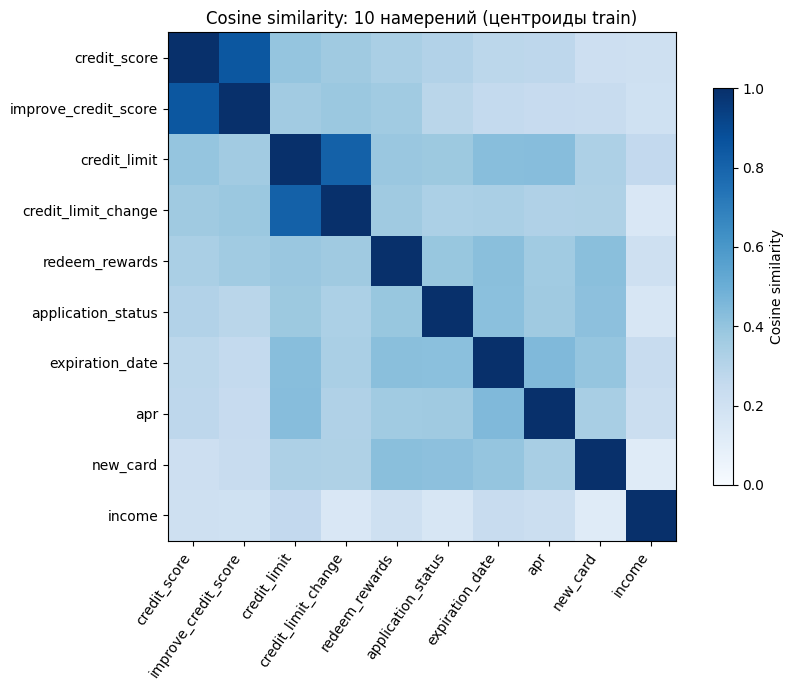

In [16]:
top_pair = pairs.iloc[0]
anchor_indices = [intent_names.index(top_pair["intent_a"]),
                  intent_names.index(top_pair["intent_b"])]
neighbor_scores = similarities[anchor_indices].sum(axis=0)
neighbor_scores[anchor_indices] = -np.inf
selected_indices = anchor_indices + list(np.argsort(neighbor_scores)[::-1][:8])
selected_names = [intent_names[index] for index in selected_indices]
selected_similarity = similarities[np.ix_(selected_indices, selected_indices)]

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(selected_similarity, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(selected_names)), selected_names, rotation=55, ha="right")
ax.set_yticks(range(len(selected_names)), selected_names)
ax.set_title("Cosine similarity: 10 намерений (центроиды train)")
fig.colorbar(image, ax=ax, shrink=0.78, label="Cosine similarity")
plt.tight_layout()
plt.show()

Самые близкие пары: `credit_score` / `improve_credit_score` (**0,850**), `todo_list` / `todo_list_update` (**0,843**) и `shopping_list` / `shopping_list_update` (**0,825**). Их запросы часто описывают один объект, но предполагают разные действия.

### 3.4. Original OOS и Held-out intents

**Original OOS** — запросы с меткой `oos` в исходном CLINC150. **Held-out intents** — известные намерения, которые будут исключены из набора поддерживаемых классов в будущих экспериментах.

Наборы для K = 10, 20, 30 ещё не зафиксированы. Поэтому здесь не сравнивается лексическое пересечение Held-out intents с конкретными наборами поддерживаемых классов. Такое сравнение возможно только после определения состава классов и их доменов. Название *near OOS* требует отдельного обоснования тематической близости.

## 4. EDA Summary

1. **Особенности данных.** Запросы короткие (медиана около 8 слов), а известные классы сбалансированы. Для TF-IDF важны повторяющиеся слова и шаблонные формулировки.
2. **Original OOS.** В `oos_val` 23 из 100 запросов полностью покрываются словарём In-Scope `train`. Незнакомые слова не могут быть единственным признаком OOS.
3. **Похожие намерения.** Наиболее близки по средним TF-IDF-векторам `credit_score` и `improve_credit_score` (0,850), `todo_list` и `todo_list_update` (0,843). Это возможные, но пока не подтверждённые источники ошибок классификации.
4. **Сравнение K.** При увеличении числа намерений будет меняться не только размер набора, но и его тематический состав. Конкретные наборы K и Held-out intents в этом EDA не выбираются.
5. **Ограничения.** Найдено 5 дословных совпадений между обучающим и оценочными In-Scope-разбиениями; их следует учитывать при интерпретации метрик. Косинусное сходство и доля знакомых слов не измеряют качество классификатора и не заменяют проверку на независимых данных.